In [18]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import cmocean as cmo
import cartopy.crs as ccrs
import gsw

from utils import get_shelf_edge, subplots_structure, nearest, prepare_eddies2plot, set_figure, make_map
from load_profiles import load_vertical_profiles

In [19]:
def get_cbar(fig, ax, cax_width=0.015, cax_pad=0.01, 
             cax_bottom=0.01, cax_height=0.5):
    """ 
    cax_pad int: x-axis location
    """
    # Get position of the last axis
    bbox = ax.get_position()
       
    cax = fig.add_axes([
        bbox.x1 + cax_pad,  # left
        cax_bottom, #bbox.y0,            # bottom
        cax_width,          # width
        cax_height         # height
    ])
    
    return fig,cax
    
def ekman_transport(tau_x, tau_y, y, H=30, rho_water=1028., tdim=0):
    """Calculate Ekman pumping from wind-stress curl.

    Args:
        curl_tau: Wind stress curl (N/m^3), 2d or 3d (for time series).
        y: Latitude grid (degrees), 2d.
        mld: mixed layer depth (m)

    Notes:
        f = Coriolis frequency (rad/s), latitude dependent.
        rho = Ocean water density (1028 kg/m^3).
        H = the surface ekman layer. It could also be the mixed layer depth

    """
    f = gsw.f(y)
    f = np.expand_dims(f, tdim)

    # gets the depth-integrated cross-shelf velocity as in Brink (2016), which is in m²/s
    Ue = (tau_y / (f*rho_water))
    Ve = - (tau_x / (f*rho_water))

    # # multiply by H to get the total transport in m³/s
    # Ue = Ue * H
    # Ve = Ve * H
    
    return Ue, Ve
    
def load_EkmanTransport(datadir):
    # loading wind shear dataset
    ds = xr.open_dataset(f"{datadir}../adaptor.mars.internal-1676897226.091868-11964-3-275141a3-cb3d-400e-8961-0e947d2ca463.nc")
    
    # creating ocean/land maks from SST
    mask = xr.where(ds['sst'].isel(time=0).isnull(), 0, 1)
    
    # empty matrix
    masked = xr.ones_like(ds['metss'])
    # replicating mask through time
    masked[:,...] = mask
    
    # gridding coordinates, necessary for wind_stress_curl() function
    x,y = np.meshgrid(ds['longitude'].values, ds['latitude'].values)
    
    # using H = 30 as an average value of the MLD computed from hydrographic data
    Ue,Ve = ekman_transport(ds['metss'], ds['mntss'], y, H=30, rho_water=1026., tdim=0)
    
    ds['Uek'] = (('time', 'latitude', 'longitude'), Ue.data)
    ds['Vek'] = (('time', 'latitude', 'longitude'), Ve.data)
    
    ds['ekmanTransport'] = np.sqrt(ds['Uek'] ** 2 + ds['Vek']**2)
    
    ds['windstress'] = np.sqrt(ds['metss'] ** 2 + ds['mntss']**2)
    
    ds['Uek'].attrs['long_name'] = 'zonal Ekman transport'
    ds['Uek'].attrs['units'] = 'm**3 s**-1'
    
    ds['Vek'].attrs['long_name'] = 'meridional Ekman transport'
    ds['Vek'].attrs['units'] = 'm**3 s**-1'
    
    ds['ekmanTransport'].attrs['long_name'] = 'Ekman transport'
    ds['ekmanTransport'].attrs['units'] = r'm$^3$ s$^{-1}$'

    return ds

In [20]:
extent = [-45, -37, -27, -19]
# create roi from extent
roi = {"lon": slice(min(extent[:2]), max(extent[:2])),
       "lat": slice(min(extent[2:]), max(extent[2:]))}

In [21]:
proj=ccrs.PlateCarree()
# extent=[-45, -39, -27, -22] #[-47.5, -37.5, -28, -20.62] # max lat fits the gebco data I have for sheld egde contour
secGloc = (-43.072, -23.033)
secGloc = (-43.072, -23.033)
idate = '2022-03-01'
edate = '2022-04-01'
lon_range = extent[:2]
lat_range = extent[2:]
time_range = pd.date_range(idate, edate, freq='1D')

depfile = '../data/gebco_2019.nc'
# before plot the map, get the sheld edge contour
shelf_edge = get_shelf_edge(depfile=depfile, extent=extent)

In [31]:
## preparing SST
datadir = '../data/AVHRR/'
ds_sst = xr.open_mfdataset(f"{datadir}/*.nc")

# selecting only valid flags data
ds_sst = ds_sst.where(ds_sst.quality_level > 3, drop=True)

# weekly avg maps
ds_weekly = ds_sst.resample(time='7D').mean()

## preparing merge
datadir = '../data/merge2/'
ds_rain = xr.open_mfdataset(f"{datadir}/*.nc", concat_dim='time', combine='nested')

# selecting only cells with precipitation higher than 0
# ds = ds.load().where(ds['prec'] > 0, drop=True)
ds_rain = ds_rain.rename({'longitude': 'lon', 'latitude': 'lat', 'rdp': 'prec'}).sel(**roi)

# loading eddies
ds_locs = xr.open_dataset(f"{datadir}../eddies_sanagu2022_daily.nc")

# loading profiles
dict_casts = load_vertical_profiles()

# loading ARGO profiles locations
ds_argo = xr.open_dataset('../data/argo/argo_profiles_all.nc')

# loading SANAGU dataset
locs = pd.read_csv(f"../data/locations.csv", index_col=0)

Processing cast1...
Processing cast2...
Processing cast3.2...
Processing cast6...
Processing cast7...


In [23]:
# computing Ekman transport
ds_quiver = load_EkmanTransport(datadir)
ds_quiver = ds_quiver.coarsen(longitude=3, latitude=3, boundary='pad').mean()

Preparing precipitation dataset

In [32]:
ds_rain

<xarray.Dataset>
Dimensions:     (time: 91, lat: 80, lon: 80)
Coordinates:
  * time        (time) datetime64[ns] 2022-01-01T12:00:00 ... 2022-04-01T12:0...
    step        timedelta64[ns] 00:00:00
    surface     float64 2.55e+03
  * lat         (lat) float64 -26.95 -26.85 -26.75 ... -19.25 -19.15 -19.05
  * lon         (lon) float64 -44.95 -44.85 -44.75 ... -37.25 -37.15 -37.05
    valid_time  (time) datetime64[ns] 2022-01-01T12:00:00 ... 2022-04-01T12:0...
Data variables:
    prec        (time, lat, lon) float32 dask.array<chunksize=(1, 80, 80), meta=np.ndarray>
    prmsl       (time, lat, lon) float32 dask.array<chunksize=(1, 80, 80), meta=np.ndarray>
Attributes:
    GRIB_edition:            2
    GRIB_centre:             255
    GRIB_centreDescription:  Not to be used
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             Not to be used
    history:                 2025-12-21T11:54 GRIB to CDM+CF via cfgrib-0.9.1...

In [33]:
ds_daily = ds_rain.resample(time='1D').mean()
# -- sea surface temperature in Celsius
# ds_plot = ds_daily.prec.sel(**roi) # -47.5, -37.5 ;;;; 

# selecting days to take a composite view after and before cold front
ds_composite_before = ds_daily.sel(time=['2022-03-10', 
                                        '2022-03-11', 
                                        '2022-03-12']).mean(dim='time')
ds_composite_before = ds_composite_before.prec.sel(**roi)


# selecting days to take a composite view after and before cold front
ds_composite_between = ds_daily.sel(time=['2022-03-13', 
                                          '2022-03-11', 
                                          '2022-03-17']).mean(dim='time')
ds_composite_between = ds_composite_between.prec.sel(**roi)

ds_composite_after = ds_daily.sel(time=['2022-03-28', 
                                        '2022-03-29', 
                                        '2022-03-30']).mean(dim='time')
ds_composite_after = ds_composite_after.prec.sel(**roi)

# renaming variables
ds_rain_before = ds_composite_before.copy(deep=True)
ds_rain_between = ds_composite_between.copy(deep=True)
ds_rain_after = ds_composite_after.copy(deep=True)

In [34]:
# 
ds_composite_before = ds_quiver.sel(time=['2022-03-10', '2022-03-11', '2022-03-12']).mean(dim='time')
ds_composite_between = ds_quiver.sel(time=slice('2022-03-13', '2022-03-17')).mean(dim='time')
ds_composite_after = ds_quiver.sel(time=slice('2022-03-28', '2022-03-30')).mean(dim='time')

# renaming variables
ds_quiver_before = ds_composite_before.copy(deep=True)
ds_quiver_between = ds_composite_between.copy(deep=True)
ds_quiver_after = ds_composite_after.copy(deep=True)

In [35]:
# filtering the ARGO and CTD by period
locs['time'] = locs['time'].apply(pd.to_datetime)

ctd_before = locs.loc[locs['time'] <= pd.to_datetime('2022-03-12'), :]
argo_before = ds_argo.where(ds_argo['TIME'] <= pd.to_datetime('2022-03-12'), drop=True)

ctd_between = locs.loc[locs['time'] <= pd.to_datetime('2022-03-17'), :]
argo_between = ds_argo.where(ds_argo['TIME'] <= pd.to_datetime('2022-03-17'), drop=True)

ctd_after = locs.loc[locs['time'] <= pd.to_datetime('2022-03-30'), :]
argo_after = ds_argo.where(ds_argo['TIME'] <= pd.to_datetime('2022-03-30'), drop=True)

In [36]:
# selecting days for eddies
ds_eddies = []
for date in time_range[[9, 10, 11]]:
    _ = ds_locs.where(ds_locs['time'] == date, drop=True)
    ds_eddies.append(_)

# preparing longitude from eddies to plot
ds_eddies_before = prepare_eddies2plot(xr.concat(ds_eddies, dim='obs'))

ds_eddies = []
for date in time_range[[12,13,14,15,16]]:
    _ = ds_locs.where(ds_locs['time'] == date, drop=True)
    ds_eddies.append(_)

# preparing longitude from eddies to plot
ds_eddies_between = prepare_eddies2plot(xr.concat(ds_eddies, dim='obs'))

ds_eddies = []
for date in time_range[[27, 28, 29]]:
    _ = ds_locs.where(ds_locs['time'] == date, drop=True)
    ds_eddies.append(_)

# preparing longitude from eddies to plot
ds_eddies_after = prepare_eddies2plot(xr.concat(ds_eddies, dim='obs'))

In [37]:
ds_daily = ds_sst.resample(time='1D').mean()

# -- sea surface temperature in Celsius
ds_plot = (ds_daily.sea_surface_temperature - 273.15).sel(**roi)

# selecting days to take a composite view after and before cold front
ds_composite_before = ds_daily.sel(time=['2022-03-10', 
                                        '2022-03-11', 
                                        '2022-03-12']).mean(dim='time')
ds_composite_before = (ds_composite_before.sea_surface_temperature - 273.15).sel(lon=slice(-47.5, -36.5), lat=slice(-16, -28), )


# selecting days to take a composite view after and before cold front
ds_composite_between = ds_daily.sel(time=['2022-03-13', 
                                          '2022-03-11', 
                                          '2022-03-17']).mean(dim='time')
ds_composite_between = (ds_composite_between.sea_surface_temperature - 273.15).sel(lon=slice(-47.5, -36.5), lat=slice(-16, -28), )

ds_composite_after = ds_daily.sel(time=['2022-03-28', 
                                        '2022-03-29', 
                                        '2022-03-30']).mean(dim='time')
ds_composite_after = (ds_composite_after.sea_surface_temperature - 273.15).sel(lon=slice(-47.5, -36.5), lat=slice(-16, -28), )

# renaming variables
ds_sst_before = ds_composite_before.copy(deep=True)
ds_sst_between = ds_composite_between.copy(deep=True)
ds_sst_after = ds_composite_after.copy(deep=True)

In [38]:
ds_sst.sel(**roi)

<xarray.Dataset>
Dimensions:                    (time: 120, lat: 0, lon: 192, nv: 2)
Coordinates:
  * lat                        (lat) float32 
  * lon                        (lon) float32 -44.98 -44.94 ... -37.06 -37.02
  * time                       (time) datetime64[ns] 2022-02-01T02:26:20 ... ...
Dimensions without coordinates: nv
Data variables: (12/15)
    aerosol_dynamic_indicator  (time, lat, lon) float32 dask.array<chunksize=(2, 0, 192), meta=np.ndarray>
    crs                        (time, lat, lon) float64 dask.array<chunksize=(2, 0, 192), meta=np.ndarray>
    dt_analysis                (time, lat, lon) float32 dask.array<chunksize=(2, 0, 192), meta=np.ndarray>
    l2p_flags                  (time, lat, lon) float64 dask.array<chunksize=(2, 0, 192), meta=np.ndarray>
    lat_bounds                 (time, lat, nv, lon) float32 dask.array<chunksize=(2, 0, 2, 192), meta=np.ndarray>
    lon_bounds                 (time, lon, nv, lat) float32 dask.array<chunksize=(2, 192, 2, 0), meta=np.ndarray>
    ...                         ...
    sea_surface_temperature    (time, lat, lon) float32 dask.array<chunksize=(2, 0, 192), meta=np.ndarray>
    sses_bias                  (time, lat, lon) float32 dask.array<chunksize=(2, 0, 192), meta=np.ndarray>
    sses_standard_deviation    (time, lat, lon) float32 dask.array<chunksize=(2, 0, 192), meta=np.ndarray>
    sst_dtime                  (time, lat, lon) float64 dask.array<chunksize=(2, 0, 192), meta=np.ndarray>
    time_bounds                (time, nv, lat, lon) datetime64[ns] dask.array<chunksize=(2, 2, 0, 192), meta=np.ndarray>
    wind_speed                 (time, lat, lon) float64 dask.array<chunksize=(2, 0, 192), meta=np.ndarray>
Attributes: (12/74)
    Conventions:                             CF-1.6, ACDD-1.3
    title:                                   AVHRR Pathfinder Version 5.3 L3-...
    summary:                                 This netCDF-4 file contains sea ...
    references:                              http://pathfinder.nodc.noaa.gov ...
    institution:                             NCEI
    history:                                 smigen_both ifile=2022032.b4kd1-...
    ...                                      ...
    cdm_data_type:                           Grid
    ncei_template_version:                   NCEI_NetCDF_Grid_Template_v2.0
    program:                                 NOAA Climate Data Record (CDR) P...
    cdr_program:                             NOAA Climate Data Record Program...
    cdr_variable:                            sea_surface_temperature
    cdr_id:                                  gov.noaa.ncdc:C00983

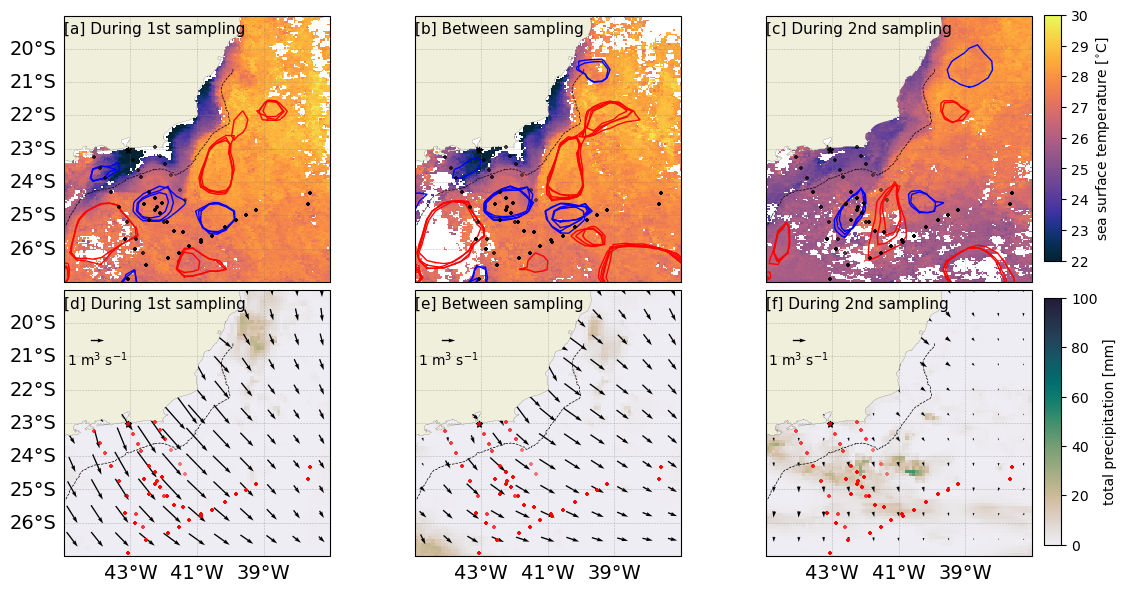

In [41]:
# plotting composites
fig = plt.figure(figsize=(30/2.54, 16/2.54)) # proportion for paper (15/2.54, 8/2.54)

#######################################
#### FIRST ROW WITH SST FROM AVHRR ####
#######################################
ax_before = fig.add_subplot(2, 3, 1, projection=ccrs.PlateCarree())
ax_before = make_map(ax=ax_before, extent=extent, deltax=2, deltay=1, drawlinebottom=False)
ax_before.set_extent(extent)

ax_between = fig.add_subplot(2, 3, 2, projection=ccrs.PlateCarree())
ax_between = make_map(ax=ax_between, extent=extent, drawlinebottom=False, drawlineleft=False, deltax=2, deltay=1)
ax_between.set_extent(extent)

ax_after = fig.add_subplot(2, 3, 3, projection=ccrs.PlateCarree())
ax_after = make_map(ax=ax_after, extent=extent, drawlinebottom=False, drawlineleft=False, deltax=2, deltay=1)
ax_after.set_extent(extent)

plots = [ds_sst_before, ds_sst_between, ds_sst_after]
axes = [ax_before, ax_between, ax_after]

for ax,p in zip(axes, plots):
    psst = p.plot.pcolormesh(ax=ax,
                          vmin=22,
                          vmax=30,
                          cmap=cmo.cm.thermal,
                          add_colorbar=False)

# adding marker and shelf edge contour
for k,ax in enumerate(axes):
    ax.scatter(secGloc[0], secGloc[1], marker='*', s=20, c='k', zorder=5)
    ax.plot(shelf_edge['lon'], shelf_edge['lat'], ls='--', c='k', lw='0.5')

    # plotting
    ax.scatter(locs['lon'], locs['lat'], s=10, zorder=11, alpha=.5, marker='+', color='k')
    ax.scatter(ds_argo['LONGITUDE'], ds_argo['LATITUDE'], color='k', zorder=11, s=10, marker='+')

# inserting anticyclonic eddies contour
for ax,eddy in zip([ax_before, ax_between, ax_after], [ds_eddies_before, ds_eddies_between, ds_eddies_after]):
    for i in range(eddy.dims['obs']):        
        _ = eddy.isel(obs=i)
        _anti = _.where(_['eddy'] == 'anticyclonic', drop=True)
        _cycl = _.where(_['eddy'] == 'cyclonic', drop=True)

        ax.plot(_anti['effective_contour_longitude'], _anti['effective_contour_latitude'], 'r', lw=1)    
        ax.plot(_cycl['effective_contour_longitude'], _cycl['effective_contour_latitude'], 'b', lw=1)

ax_before.set_title('[a] During 1st sampling', loc='left', fontsize=11, y=.9)
ax_between.set_title('[b] Between sampling', loc='left', fontsize=11, y=.9)
ax_after.set_title('[c] During 2nd sampling', loc='left', fontsize=11, y=.9)

# # despite CFE and AgR on the first two maps
# for ax in [ax_before, ax_between, ax_after]:
#     t = ax.annotate("CFE",xy=(-42, -24.5), xytext=(-40.2, -23.5),
#              arrowprops={"width": 2, "headwidth": 5, "headlength": 5, 'color': 'k'},
#              horizontalalignment="center", fontsize=14)
#     t.set_bbox(dict(facecolor='white', alpha=0.4, edgecolor='white'))
    
# t = ax_before.annotate("AgR",xy=(-41., -26.5), xytext=(-39.2, -25.5),
#              arrowprops={"width": 2, "headwidth": 5, "headlength": 5, 'color': 'k'},
#              horizontalalignment="center", fontsize=14)
# t.set_bbox(dict(facecolor='white', alpha=0.4, edgecolor='white'))

########################################################
#### SECOND ROW WITH TOTAL PRECIPITATION FROM MERGE ####
########################################################
ax_before = fig.add_subplot(2, 3, 4, projection=ccrs.PlateCarree())
ax_before = make_map(ax=ax_before, extent=extent, deltax=2, deltay=1)
ax_before.set_extent(extent)

ax_between = fig.add_subplot(2, 3, 5, projection=ccrs.PlateCarree())
ax_between = make_map(ax=ax_between, extent=extent, drawlineleft=False, deltax=2, deltay=1)
ax_between.set_extent(extent)

ax_after = fig.add_subplot(2, 3, 6, projection=ccrs.PlateCarree())
ax_after = make_map(ax=ax_after, extent=extent, drawlineleft=False, deltax=2, deltay=1)
ax_after.set_extent(extent)

plots = [ds_rain_before, ds_rain_between, ds_rain_after]
axes = [ax_before, ax_between, ax_after]

for ax,p in zip(axes, plots):
    prain = p.plot.pcolormesh(ax=ax,
                          vmin=0,
                          vmax=100,
                          cmap=cmo.cm.rain,
                          add_colorbar=False)

# PLOTTING EKMAN TRANSPORT
quiver_kwargs = dict(scale=20, width=.005, color='k', add_guide=False)
quiverkey=[-44., -20.5, 1, r'1 m$^3$ s$^{-1}$']
quiverkey_kws=dict(labelpos='S', color='k', coordinates='data')

plots = [ds_quiver_before, ds_quiver_between, ds_quiver_after]
axes = [ax_before, ax_between, ax_after]

for ax,q in zip(axes, plots):
    _ = q.plot.quiver(ax=ax, 
                      x='longitude', y='latitude', 
                      u='Uek', v='Vek',
                      **quiver_kwargs)

    qk = ax.quiverkey(_,
                      quiverkey[0], # x position
                      quiverkey[1], # y position
                      quiverkey[2], # unit 
                      quiverkey[3], # label
                      **quiverkey_kws).set_zorder(11)

# adding marker and shelf edge contour
for k,ax in enumerate(axes):
    ax.scatter(secGloc[0], secGloc[1], marker='*', s=20, c='k', zorder=5)
    ax.plot(shelf_edge['lon'], shelf_edge['lat'], ls='--', c='k', lw='0.5')

    # plotting
    ax.scatter(locs['lon'], locs['lat'], s=10, zorder=11, alpha=.5, marker='+', color='r')
    ax.scatter(ds_argo['LONGITUDE'], ds_argo['LATITUDE'], color='r', zorder=11, s=10, marker='+')

_ = [ax.set_title('') for ax in axes]

ax_before.set_title('[d] During 1st sampling', loc='left', fontsize=11, y=.9)
ax_between.set_title('[e] Between sampling', loc='left', fontsize=11, y=.9)
ax_after.set_title('[f] During 2nd sampling', loc='left', fontsize=11, y=.9)

plt.tight_layout()
plt.subplots_adjust(top=0.952,
                    bottom=0.094,
                    left=0.083,
                    right=0.96,
                    hspace=0.03,
                    wspace=0.05)

# Add sst colorbar
fig, cax_sst = get_cbar(fig, ax_after, cax_pad=0.01, 
                         cax_bottom=0.563, cax_height=0.39)
cbsst = fig.colorbar(psst, cax=cax_sst)
cbsst.set_label(label='sea surface temperature [$^{\circ}$C]', size=10)

# Add total precipition colorbar
fig, cax_rain = get_cbar(fig, ax_after, cax_pad=0.01, 
                         cax_bottom=0.112, cax_height=0.392)
cbrain = fig.colorbar(prain, cax=cax_rain)
cbrain.set_label(label='total precipitation [mm]', size=10)

fig.patch.set_alpha(1.0)
plt.savefig('../figures/manuscript/00_manuscript_oceanographicContext.png', bbox_inches="tight", dpi=300)